# Gaussian experiment, from formulas to code

This notebook follows the six stages: train the
selected `pca_balanced` DFM, freeze it, compare Raw H (without refinements)
with Refined H (all five refinements), then generate and assess conditional returns.

Use $R$ for clean population returns, $s$ for forward OU noising time,
$t$ for elapsed generation time, and $\tau=T-t_0$. The ambient generated state is
$X_t$ and the reduced conditioning state is $Y_t=G_tX_t$. Mathematical vectors are
columns; code stores observation batches as rows. Both the notebook and this document reserve $Y$ for the reduced state.


## Configuration

The notebook defaults to `MODE="standard"`; set `MODE="smoke"` for a shorter
execution.

| Setting | Notebook smoke | Notebook standard (default) |
| --- | ---: | ---: |
| Assets / factors | 12 / 8 | 128 / 8 |
| DFM train / validation / evaluation observations | 2,048 / 512 / 512 | 12,000 / 3,000 / 3,000 |
| DFM epochs / hidden widths | 15 / (32, 32) | 1,000 / (64, 64) |
| Integration steps | 100 | 400 |
| H train / validation / test trajectories | 2,048 / 1,024 / 1,024 | 10,000 / 2,000 / 2,000 |
| H epochs / hidden widths | 10 / (64, 64) | 200 / (64, 64) |
| Accepted samples per DFM rejection stream | 128 | 1,000 |
| Proposal cap per DFM rejection stream | 10,000 | 50,000 |


In [15]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict, replace
import sys
import time

import numpy as np
import pandas as pd
from scipy.stats import kstest
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "DFM.py").exists():
    raise RuntimeError("Run this notebook with the repository as working directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from reference import FrozenDFMReference
from sampling import generate_samples
from synthetic_conditional_truth import make_population


In [16]:
from synthetic_benchmark.configuration import Config, write_json


In [17]:
import os
# Set to a saved run to keep its DFM fixed; None trains a new DFM.
FROZEN_DFM_RUN = os.environ.get("SYNTHETIC_FROZEN_DFM_RUN")
MODE = "standard"  # smoke reduces dimensions and both DFM and H training budgets.
CONFIG_OVERRIDES = {
    # Selected using observed validation returns; the objective is explained below.
    "dfm_initialization": "pca",
    "dfm_time_sampling": "log_balanced",
    "dfm_loading_lr_scale": 0.1,
    "dfm_loading_warmup_epochs": 100,
    "lr": 1e-3,
    "d": 12 if MODE == "smoke" else 128,
    "k": 8,
    # "seeds": (42,),
    # "n_train": 12_000, "n_val": 3_000, "n_eval": 3_000,
    # "dfm_epochs": 1_000, "steps": 400,
    # "T": 8.0, "t0": 0.005, "width": 64,
    # "batch": 256, "device": "cpu",
}
CONFIG = replace(Config.preset(MODE), **CONFIG_OVERRIDES)
OUTPUT = ROOT / "artifacts" / "synthetic_unconditional_benchmark" / (
    MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
display(pd.Series(asdict(CONFIG), name="Effective DFM configuration").to_frame())
print(f"DFM training: {CONFIG.dfm_epochs:,} epochs per seed")
print("Artifacts:", OUTPUT)


,Effective DFM configuration
mode,standard
d,128
k,8
seeds,"(42,)"
cases,"(gaussian,)"
n_train,12000
n_val,3000
n_eval,3000
dfm_epochs,1000
steps,400


DFM training: 1,000 epochs per seed
Artifacts: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z


## 1. Construct the synthetic population

Following the synthetic-data construction in Section 6 and Appendix D of Xu and coauthors, we generate Gaussian factors with heterogeneous means and volatilities, independent Gaussian loading entries, and heteroskedastic Gaussian idiosyncratic noise. We express this model in orthonormal factor coordinates through a QR decomposition and a corresponding transformation of the factor distribution. This reparameterization preserves the return distribution exactly. The Gaussian specification provides analytical unconditional and portfolio-event-conditional benchmarks for assessing both the fitted DFM and the additional conditioning procedure.

The default standard experiment uses $d=128,k=8$. It follows the parameter-generation mechanism of Xu and coauthors at smaller dimensions than their $d=2048,k=16$. Smoke mode uses $d=12,k=8$ with reduced training budgets.

Draw once, with this project's population-design seed 912:
$$
\mu_{F,j}\overset{\rm iid}{\sim}\mathcal U(0,0.1),\quad
\sigma_{F,j}=1.5\mu_{F,j},\quad \Sigma_F=\operatorname{diag}(\sigma_{F,j}^2),
$$
$$
\beta_{ij}\overset{\rm iid}{\sim}\mathcal N(0,1),\quad
\sigma_{\varepsilon,i}\overset{\rm iid}{\sim}\mathcal U(0,0.4),\quad
D_i=\sigma_{\varepsilon,i}^2.
$$

Hold these parameters fixed across independent training, validation, and evaluation draws:
$$
F\sim\mathcal N(\mu_F,\Sigma_F),\quad
\varepsilon\sim\mathcal N(0,\operatorname{diag}(D)),\quad F\perp\varepsilon,\quad
R=\beta F+\varepsilon.
$$

Reduced QR, with nonnegative diagonal of $A$, gives the exact change of coordinates
$$
\beta=BA,\quad B^\top B=I_k,\quad \widetilde F=AF,\quad
\widetilde\mu_F=A\mu_F,\quad \widetilde\Sigma_F=A\Sigma_FA^\top,
$$
$$
R=B\widetilde F+\varepsilon,\quad
\mu=B\widetilde\mu_F=\beta\mu_F,\quad
\Sigma=B\widetilde\Sigma_FB^\top+\operatorname{diag}(D)
=\beta\Sigma_F\beta^\top+\operatorname{diag}(D).
$$

Original factors are independent; transformed factors are generally correlated. `m[0]` and `S[0]` store their transformed mean and **full** covariance. `sample_returns` returns $\widetilde F$, associated with stored $B$.

The equal-weight portfolio and population event remain
$$
w=\frac{\mathbf1}{d},\quad P=w^\top R\sim\mathcal N(a,v),\quad
 a=w^\top\mu,\quad v=w^\top\Sigma w,\quad
 C_q=a+\sqrt v\,\Phi^{-1}(q),\quad q=0.05.
$$

`sample` uses factor-based Gaussian draws and an exact conditional correction when requested. The DFM receives returns only and learns its own $V$. Full construction details go to `population.json`; DFM/H checkpoints record design, seed, dimensions, and QR convention. Old designs require fresh DFM and H training; their artifacts are preserved.

| Formula / operation | Function in [synthetic_conditional_truth.py](synthetic_conditional_truth.py) | Inputs → outputs |
| --- | --- | --- |
| Fix $B,D,m,S$ | `make_population(d, "gaussian", k=k)` | Dimensions → `FactorPopulation` |
| Draw $R\sim N(\mu,\Sigma)$ | `population.sample(n, rng)` | Count and NumPy generator → float64 `[n,d]` |
| Draw explicit $F,\varepsilon$ | `population.sample_returns(n, rng)` | Count and generator → returns `[n,d]`, factors `[n,k]`, regime labels `[n]` |
| Compute $\mu,\Sigma$ | `population.moments()` | No arguments → `[d]`, `[d,d]` |
| Choose $C$ with $P(w^\top R\le C)=0.05$ | `population.threshold(0.05)` | Tail probability → scalar threshold |

The notebook uses `sample`, drawing through the factor construction to avoid a
dense covariance decomposition. `sample_returns` also exposes the transformed factors.

`Streams(42)` in [configuration.py](synthetic_benchmark/configuration.py)
creates separate generators for observations, validation, two truth draws, DFM
noise, validation noise, model initialization, and generation. The population
design seed is separate from the experiment's training seed.


The standard experiment matches the paper's **construction** but not its **dimensions**: it uses $d=128,k=8$ instead of $d=2048,k=16$. A **full experimental replication** would also require the paper's dimensions, sample-size study, preprocessing, architecture, and training protocol. We model raw returns without centering, variance-based asset ordering, or image reshaping. A new population seed gives a different realization, not the paper's exact numerical dataset.


In [18]:
population = make_population(CONFIG.d, "gaussian", k=CONFIG.k)
population_mean, population_covariance = population.moments()
raw_population = population.construction
print(f"Actual experiment: d={population.d}, k={population.k}; population seed={raw_population['population_seed']}")
display(pd.DataFrame({
    "original_factor_mean": raw_population["mu_F"],
    "original_factor_std": raw_population["sigma_F"],
    "transformed_factor_mean": population.m[0],
}).rename_axis("factor"))
display(pd.DataFrame(population.S[0]).rename_axis("transformed factor covariance"))
display(pd.Series({
    "residual_std_min": np.sqrt(population.D).min(),
    "residual_std_max": np.sqrt(population.D).max(),
    "orthonormality_error": np.linalg.norm(population.B.T @ population.B - np.eye(population.k)),
    "portfolio_mean": population.w @ population_mean,
    "portfolio_variance": population.w @ population_covariance @ population.w,
    "portfolio_5pct_threshold": population.threshold(0.05),
}, name="Population truth").to_frame())


Actual experiment: d=128, k=8; population seed=912


,original_factor_mean,original_factor_std,transformed_factor_mean
factor,,,
0,0.099142,0.148713,1.032589
1,0.023004,0.034506,0.400856
2,0.016081,0.024121,0.287270
3,0.063531,0.095296,0.803504
4,0.000997,0.001496,-0.003291
5,0.090975,0.136463,1.181938
6,0.041653,0.062480,0.591657
7,0.083942,0.125913,1.005471


,0,1,2,3,4,5,6,7
transformed factor covariance,,,,,,,,
0,2.596574,0.044416,-0.044654,0.004249,-0.009335,-0.232424,0.042169,-0.044818
1,0.044416,0.255799,-0.076368,0.001402,0.018109,-0.228127,0.108677,0.361831
2,-0.044654,-0.076368,0.166784,-0.014640,-0.019209,0.467187,0.022405,-0.122036
3,0.004249,0.001402,-0.014640,1.329646,-0.025503,0.339425,-0.009578,-0.255606
4,-0.009335,0.018109,-0.019209,-0.025503,0.026011,-0.018176,-0.059559,0.165913
5,-0.232424,-0.228127,0.467187,0.339425,-0.018176,2.512196,0.078861,0.168002
6,0.042169,0.108677,0.022405,-0.009578,-0.059559,0.078861,0.519670,0.290915
7,-0.044818,0.361831,-0.122036,-0.255606,0.165913,0.168002,0.290915,2.274686


,Population truth
residual_std_min,3.031436e-03
residual_std_max,3.988170e-01
orthonormality_error,1.457449e-15
portfolio_mean,4.104117e-02
portfolio_variance,1.277342e-03
portfolio_5pct_threshold,-1.774577e-02


## 2. Train and sample the unconditional DFM

We introduce two refinements to improve the unguided DFM's approximation of the
return distribution, particularly its covariance structure:

1. **Observation-based initialization and staged loading updates.** The loading matrix determines which directions of joint return variation the factor network sees. Starting from random directions makes the network learn this representation at the same time as it learns the score. We instead initialize the loadings with the principal components of the training returns and initialize the idiosyncratic variances from the remaining variation. We first hold the loadings fixed so the other parameters can adapt to these coordinates, then update them at a smaller learning rate. This provides an informed starting point while allowing the representation to adjust during score learning.

2. **Log-spaced noising times and noise-variance-weighted score matching.** Uniform time sampling devotes few training examples to the small noising times that correspond to the final stages of generation, where the model must recover the detailed return distribution. Sampling times on a logarithmic scale gives these small times more coverage. At the same time, the denoising target grows as the noise level decreases; weighting the squared error by the noise variance counteracts this growth. Together, these choices aim to improve score learning across noise levels without allowing the scale of the low-noise target to dominate the loss.

The notebook combines refinements (1) and (2) in **`pca_balanced`**, selected for
covariance recovery against observed validation returns.
The mathematical details below specify this setup;
`scripts/compare_xu_training.py` reproduces comparisons across training setups.

For clean returns $R$, the forward OU corruption is

$$
R_s=\alpha_s R+\sqrt{h_s}\,\xi,\qquad
\alpha_s=e^{-s/2},\quad h_s=1-e^{-s},\quad \xi\sim N(0,I_d).
$$

[`UnconditionalDFM.q_sample`](DFM.py) maps returns `[N,d]`, times `[N,1]`, and
noise `[N,d]` to corrupted returns `[N,d]`.

The learned score in [`FactorScoreNetwork.forward`](NeuralNets.py) is

$$
s_\theta(r,s)=\alpha_s D_s Vg_\zeta(V^\top D_s r,s)-D_sr,\qquad
D_s=\operatorname{diag}(h_s+\alpha_s^2 c_i)^{-1}.
$$

Here $V\in\mathbb R^{d\times k}$, $c_i=2\operatorname{sigmoid}(c_{\rm raw,i})$,
and the two-hidden-layer ReLU MLP $g_\zeta$ are learned jointly. The MLP maps
`[N,k+1]` to `[N,k]`; the complete score maps `[N,d]` and `[N,1]` to `[N,d]`.
The fitted $V,c$ need not equal the population $B,D$.

**Initialization and optimization (refinement 1).** From the covariance of
centered training observations, take the leading $k$ eigenvectors as $V_0$.
We initialize the idiosyncratic variances from the variation left unexplained
by these principal components.

Only training observations enter this initializer; the DFM subsequently models
raw returns. Adam updates $c_{\rm raw}$ and $\zeta$ at learning rate $10^{-3}$.
Hold $V$ fixed for 100 epochs, then update it at $10^{-4}$;
`project_orthogonal()` restores orthonormal columns by QR after each step.

**Time sampling and denoising loss (refinement 2).** Sample forward noising
times from the log-uniform density

$$
u\sim\mathcal U(0,1),\qquad s=t_0(T/t_0)^u,\qquad
q(s)=\frac{1}{s\log(T/t_0)},\quad t_0\le s\le T,
$$

and minimize the noise-variance-weighted objective

$$
\mathcal L_{\rm DFM}(\theta)=
\mathbb E_{R,\,s\sim q,\,\xi}
\left[h_s\left\|s_\theta(R_s,s)+\frac{\xi}{\sqrt{h_s}}\right\|_2^2\right],
\qquad e_* = \arg\min_e\widehat{\mathcal L}_{\rm val}(\theta_e).
$$

The squared norm sums over assets; the empirical loss averages over
observations. The target $-\xi/\sqrt{h_s}$ has expected squared norm $d/h_s$,
so multiplication by $h_s$ removes this target-scale growth. Log-time sampling
and this weight intentionally change the time weighting of the original
uniform-time objective. Because the weights are positive and depend only on
time, the unrestricted population minimizer remains the true score at each
noising time.

Validation evaluates this same objective with fixed independent times and
noise. The lowest-loss checkpoint $e_*$ is restored and frozen. The notebook
implements both refinements through
[`fit_dfm`](synthetic_benchmark/unconditional.py), called by
`fit_and_save_dfm`; it returns the model, per-epoch losses, and selected epoch.
Population moments and true factors are not supplied to the optimizer.


In [19]:
from synthetic_benchmark.unconditional import (
    initialize_unconditional_run, prepare_unconditional_case,
    fit_and_save_dfm, evaluate_unconditional_samples,
    save_unconditional_case, save_unconditional_summary,
)


### Unconditional sampling

After fitting, [`generate_samples`](sampling.py) approximates

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)\right]dt+dW_t,
\qquad X_0\sim N(0,I_d),\quad 0\le t\le\tau.
$$

With $\Delta t=\tau/J$, it applies Euler–Maruyama:
$X_{j+1}=X_j+[X_j/2+s_\theta(X_j,T-t_j)]\Delta t+
\sqrt{\Delta t}\xi_j$.
`generate_samples(reference, n, num_steps=J, generator=rng)` returns `[n,d]`;
`return_trajectory=True` returns `[n,J+1,d]`, including both endpoints.
Finite $T$, positive $t_0$, fitting error, and discretization all affect agreement
with the clean Gaussian population.


In [20]:
from synthetic_benchmark.reporting import plot_dfm_validation


### Execute training and evaluation


In [21]:
if tuple(CONFIG.cases) != ("gaussian",):
    raise RuntimeError("Stale simulation configuration: restart the kernel, reload this Gaussian notebook, and run all cells in order.")

initialize_unconditional_run(OUTPUT, CONFIG)
if FROZEN_DFM_RUN:
    from synthetic_benchmark.conditional import reuse_frozen_unconditional_run
    metrics, numeric = reuse_frozen_unconditional_run(FROZEN_DFM_RUN, OUTPUT, CONFIG)
else:
    started = time.perf_counter()
    rows = []
    for seed in CONFIG.seeds:
        for case in ("gaussian",):
            folder, streams, pop = prepare_unconditional_case(OUTPUT, CONFIG, case, seed)
            train = pop.sample(CONFIG.n_train, streams.np("train"))
            val = pop.sample(CONFIG.n_val, streams.np("validation"))
            truth = pop.sample(CONFIG.n_eval, streams.np("truth"))
            truth2 = pop.sample(CONFIG.n_eval, streams.np("truth2"))
    
            model, history, selected, fit_seconds = fit_and_save_dfm(
                train, val, CONFIG, streams, pop, case, folder,
            )
            reference = FrozenDFMReference(model)
            gen_start = time.perf_counter()
            generated = generate_samples(
                reference, CONFIG.n_eval, num_steps=CONFIG.steps,
                generator=streams.torch("generated", CONFIG.device),
            ).cpu().numpy()
            generation_seconds = time.perf_counter() - gen_start
    
            result, baseline = evaluate_unconditional_samples(
                generated, truth, truth2, pop, reference, CONFIG, case, seed,
                fit_seconds, generation_seconds,
            )
            rows.extend([result, baseline])
            save_unconditional_case(folder, case, generated, truth, truth2, pop, result, baseline)
    metrics, numeric = save_unconditional_summary(rows, OUTPUT, started)


Running gaussian, seed=42, d=128


Assets: 128; population factors: 8; DFM factors: 8
Finished: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z


In [22]:
columns = ["case", "seed", "method", "mean_error", "covariance_error", "correlation_error", "portfolio_ks", "portfolio_w1", "sliced_w1", "mmd2_unbiased"]
display(metrics[columns].round(4))
display(metrics.loc[metrics.method == "DFM", ["case", "seed", "loading_projection_error", "event_0.1", "event_0.05", "event_0.01"]].round(4))

,case,seed,method,mean_error,covariance_error,correlation_error,portfolio_ks,portfolio_w1,sliced_w1,mmd2_unbiased
0,gaussian,42,DFM,0.1150,0.1392,0.2310,0.015,0.0009,0.0384,0.0026
1,gaussian,42,truth-vs-truth,0.0169,0.0574,0.0529,0.018,0.0008,0.0130,0.0005


,case,seed,loading_projection_error,event_0.1,event_0.05,event_0.01
0,gaussian,42,0.3572,0.1107,0.057,0.0097


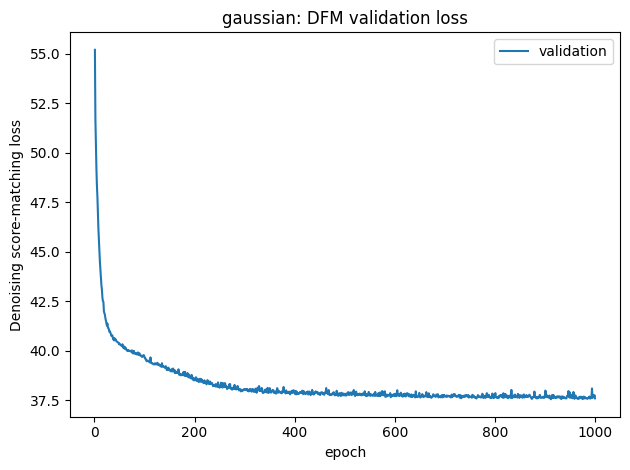

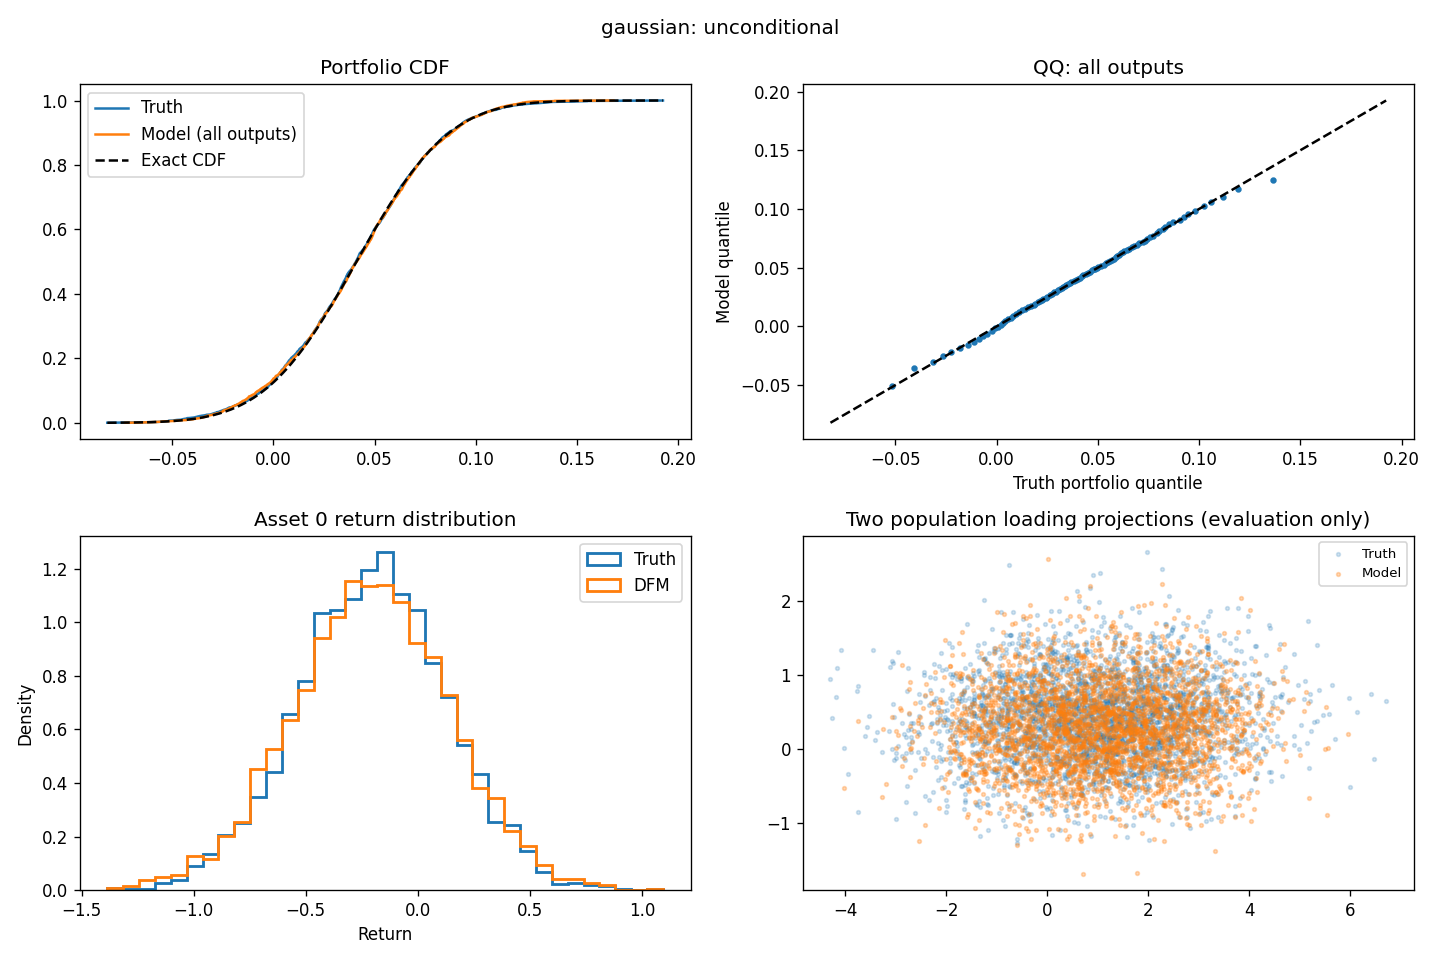

In [23]:
for case in ("gaussian",):
    folder = OUTPUT / f"{case}_seed{CONFIG.seeds[0]}_primary"
    plot_dfm_validation(folder, case)
    display(Image(filename=str(folder / "unconditional.png")))


### Monte Carlo reference level


In [24]:
primary = metrics.loc[
    (metrics.case == "gaussian") & (metrics.seed == CONFIG.seeds[0])
].set_index("method")
report_metrics = ["covariance_error", "portfolio_ks", "sliced_w1"]
recovery_comparison = primary.loc[["DFM", "truth-vs-truth"], report_metrics].T
recovery_comparison["DFM / MC baseline"] = (
    recovery_comparison["DFM"] / recovery_comparison["truth-vs-truth"].replace(0, np.nan)
)
display(recovery_comparison.round(4))
text = (
    f"Gaussian benchmark: seed {CONFIG.seeds[0]}, d={CONFIG.d}, k={CONFIG.k}.\n\n"
    + "```text\n" + recovery_comparison.to_string() + "\n```\n\n"
    + "The independent truth comparison describes Monte Carlo variability. "
    + "These ratios do not establish conditional or unconditional recovery.\n"
)
(OUTPUT / "conclusions.md").write_text(text)


method,DFM,truth-vs-truth,DFM / MC baseline
covariance_error,0.1392,0.0574,2.4271
portfolio_ks,0.0150,0.0180,0.8333
sliced_w1,0.0384,0.0130,2.9663


440

## 3. Freeze the DFM and construct conditioning coordinates

[`FrozenDFMReference(model)`](reference.py) deep-copies the trained score,
freezes every parameter, and fixes its time settings. Input derivatives remain
available, so freezing the DFM does not prevent guidance differentiation.

Let $s=T-t$, $\Lambda_s=D_s^{-1}$, and

$$
\ell_t=\frac{\alpha_s}{\alpha_{t_0}}D_s\Lambda_{t_0}w,
\qquad
G_t=\begin{bmatrix}V^\top D_s\\\ell_t^\top\end{bmatrix},
\qquad
Y_t=G_tX_t=(Z_t,U_t).
$$

`reference.G(t, w)` takes a scalar generation time and `[d]` weights and returns
`[k+1,d]`. Batched times return `[N,k+1,d]`. `HNetwork.features(t,x)` maps `[N,d]`
to `[N,k+1]`; at a shared scalar time this is `x @ G(t).T`.

At $t=\tau$, $s=t_0$ and $D_{t_0}\Lambda_{t_0}=I$, hence
$\ell_\tau=w$ and $U_\tau=w^\top X_\tau$. This keeps the entire portfolio event,
including the residual return contribution. Earlier $U_t$ generally differs from
$w^\top X_t$. Neither $G_t$ nor its noise covariance needs an inverse.

[`ConditioningConfig(w,C)`](conditioning.py) fixes the event.
`initialize_h(..., log_remaining_time=True)` in
[conditional.py](synthetic_benchmark/conditional.py) returns this event, an
`HNetwork`, and its `DFMHGuidance`. The event uses raw synthetic return coordinates.

For the continuous reference SDE, the reduced process has diffusion covariance
$A_t=G_tG_t^\top$. With $n=g_\zeta(z,s)$, its closed drift is

$$
\mu_Z(t,y)=-\tfrac12z+\alpha_s V^\top D_s^2Vn,\qquad
\mu_U(t,y)=\frac{\alpha_s^2}{\alpha_{t_0}}
w^\top\Lambda_{t_0}D_s^2Vn.
$$

These formulas are `HNetwork.mu(t,y)` (`[N,k+1]` → `[N,k+1]`) and
`HNetwork.A(t)` (scalar time → `[k+1,k+1]`). The notebook generates full ambient
paths and projects them; it does not integrate `mu` to construct training data.


## 4. Compare Raw H and Refined H

The continuous-time target is

$$
H(t,y)=P(U_\tau\le C\mid Y_t=y),\qquad
H(\tau,y)=\mathbf1\{u\le C\}.
$$

`h.sample_trajectories(N, num_steps=J, generator=rng, batch_size=256)` generates
unguided paths from the frozen DFM with ordinary Gaussian starts. For path $i$,
it assigns one label $L_i=\mathbf1\{w^\top X_\tau^{(i)}\le C\}$ and retains
$(t_j,G_{t_j}X_{t_j}^{(i)})$ at every preterminal time. It returns `TerminalLabelData`:

| Field | Shape | Meaning |
| --- | --- | --- |
| `times` | `[J]` | Generation times from zero, excluding $\tau$ |
| `features` | `[N,J,k+1]` | Projected ambient path states |
| `labels` | `[N,1]` | One terminal event indicator per path |
| `weights` | `[J]` | $\omega_j=\Delta t_j/\tau$, summing to one |
| `last_probabilities` | `[N,1]` | Exact final Euler-step event probabilities |
| `last_states` | `[N,d]` | Ambient states before the final step, for diagnostics |

The notebook trains two H models on the **same frozen DFM and the same training,
validation, and test trajectories**. Here **Raw H** means the baseline without
any of the five refinements: unstandardized coordinates, normalized time only,
binary terminal labels at every preterminal time, ordinary interval weights
$\omega_j$, and MSE (Brier) loss. Raw H uses every stored time per trajectory.
Both variants use the same hidden widths, epochs, and learning rate; each selects
its own checkpoint using its configured validation objective. Their validation
loss values have different meanings (MSE versus BCE).

**Refined H** adds the following five refinements:

1. **Standardization of the reduced coordinates.** We standardize each reduced coordinate using time-dependent means and standard deviations estimated from the training trajectories. This prevents coordinates with larger magnitudes from dominating the network inputs and helps limit saturation of the Tanh activations. Standardization remains inside the network’s computational graph, preserving the chain rule used for guidance.

2. **An additional temporal input.** Alongside normalized time, we provide the log remaining time,
   $$
   \log\left(\frac{\max(\tau-t,\Delta t)}{\tau}\right),
   $$
   bringing the input dimension to $k+3$. This representation helps the network resolve changes near the terminal boundary, where the event probability becomes increasingly sharp. The floor $\Delta t$ keeps the logarithm finite.

3. **An exact probability target at the last preterminal time.** At earlier times, the target remains the binary terminal label. At the last preterminal time, we replace this label with the exact event probability for the frozen DFM’s final Euler step. This integrates out the final Gaussian noise instead of relying on a single realised outcome. The binary label is already a valid target in expectation; the replacement reduces its sampling noise and provides more informative supervision.

4. **Greater emphasis on late times.** We increase the loss weights near the terminal time, particularly at the last preterminal step. As less time remains for future noise to influence the outcome, the event probability transitions more sharply around the threshold. Allocating more training effort to this region aims to improve its approximation. The weights depend only on time, preserving the ideal conditional-probability target.

5. **Binary cross-entropy instead of mean squared error.** We use BCE, implemented directly from logits for numerical stability. For a sigmoid output, its gradient with respect to the logit is $H_\phi-p$, whereas MSE introduces an additional factor proportional to $H_\phi(1-H_\phi)$. BCE therefore avoids this extra attenuation when predictions are confident but incorrect.

With positive time-dependent weights, the unrestricted population minimizer remains the conditional event probability,
$$
H_*(t,y)=\mathbb P(E\mid Y_t=y).
$$
In continuous time, this function defines the Doob $h$-transform through its logarithmic gradient. In the notebook, the training target corresponds to the discretized DFM and the information retained in the reduced coordinates.

`sample_h_training_data` generates independent training, validation, and test
sets of whole trajectories, checking both label classes. Terminal outcomes supply
the labels; network inputs include only preterminal states.

The `(64,64)` Tanh [`HNetwork`](h_model.py) implements refinements (1) and (2):

$$
\widetilde y=\frac{y-m_t^Y}{\sigma_t^Y},\qquad
H_\phi(t,y)=\operatorname{sigmoid}\!\left(
f_\phi\!\left(\widetilde y,\frac t\tau,
\log\frac{\max(\tau-t,\Delta t)}{\tau}\right)\right).
$$

The coordinatewise statistics are fitted on training paths only, interpolated in
time, and saved with the checkpoint; scales have a floor of $10^{-6}$.

`h_time_weights` defines the time probabilities (refinements 3 and 4)

$$
q_j=0.5\omega_j+
0.4\frac{\omega_j/(\tau-t_j)}{\sum_l\omega_l/(\tau-t_l)}
+0.1\mathbf1\{j=J-1\},\qquad \sum_jq_j=1.
$$

With $b_j(x)=\tfrac12x+s_\theta(x,T-t_j)$, the targets are

$$
p_{ij}=\begin{cases}
L_i,&j<J-1,\\[2mm]
\displaystyle\Phi\!\left(
\frac{C-w^\top[X_{J-1}^{(i)}+b_{J-1}(X_{J-1}^{(i)})\Delta t]}
{\sqrt{\Delta t}\,\|w\|_2}\right),&j=J-1.
\end{cases}
$$

The last target is exact for one frozen ambient Euler step conditional on full
$x$; pointwise representability from reduced $G_tx$ is not assumed.

The objective is (refinement 5)

$$
\mathcal L_H=\frac1N\sum_{i=1}^N\sum_{j=0}^{J-1}q_j
\operatorname{BCE}\!\left(H_\phi(t_j,Y_{t_j}^{(i)}),p_{ij}\right).
$$

`train_h` updates only H using Adam at $10^{-3}$, with 64 trajectories per batch
and 32 independently sampled time indices with replacement per path and epoch.
Sampling from $q$ estimates this objective directly, without class balancing.
Training runs for 200 epochs (10 in smoke), restoring the checkpoint with the
lowest deterministic weighted BCE over all validation times. Test data and
generated-distribution metrics do not select the checkpoint.

`fit_and_evaluate_h` verifies that the DFM is unchanged and saves held-out Brier
loss against a constant baseline, calibration, Tanh saturation, and last-step
gradient diagnostics. Separate streams provide 1,000 guided and rejection
validation samples (128 in smoke) before final reporting, without automatic
retuning.


## 5. Generate conditional returns

The conditional initial density for exact H is proportional to
$H(0,G_0x)\varphi_d(x)$. Therefore
[`sample_conditional_initial`](guided_sampling.py) proposes $x\sim N(0,I_d)$
and accepts with probability $H_\phi(0,G_0x)$. It returns accepted states `[N,d]`
and acceptance diagnostics. This samples the normalized *learned* H tilt; it
equals the desired initial law only for exact H. Exhausting its proposal budget
raises an error.

For exact continuous-time H, the ambient Doob correction is

$$
\nabla_x\log H(t,G_tx)=G_t^\top\nabla_y\log H(t,G_tx),
$$

and the guided SDE is

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)
+G_t^\top\nabla_y\log H(t,G_tX_t)\right]dt+dW_t.
$$

`DFMHGuidance(h)(state, time)` returns this additive `[N,d]` drift.

`sample_h_guided` first draws all accepted starts, then calls `generate_samples`
in batches with `guidance_fn=guidance` and scale 1. It returns all terminal rows
as NumPy `[N,d]`, including event violations.

The exact conditioning formula describes a continuous diffusion. A learned H and
finite-step Euler integration do not guarantee exact samples from the discrete
reference sampler conditioned on its terminal event. This is why independent
DFM rejection remains a necessary comparison.


## 6. Evaluate the distribution, including joint structure

`assess_conditional_samples` in [conditional.py](synthetic_benchmark/conditional.py)
calls `sample_dfm_rejection` twice with independent seeds. Each stream samples
the same frozen unguided DFM on the same grid and retains $w^\top X_\tau\le C$.
These are benchmarks for the numerical DFM's conditional law, which may differ
from the population conditional law.

The comparison separates three questions:

| Comparison | What it assesses |
| --- | --- |
| DFM rejection vs population conditional truth | Error in the learned numerical reference law |
| Raw H-guided vs DFM rejection | Error introduced by learned conditioning and guided integration |
| Raw H-guided vs population conditional truth | Combined conditional-generation error |
| Event-filtered H-guided vs either reference | Quality of the retained guided subset |
| Independent truth vs truth, rejection vs rejection | Descriptive Monte Carlo reference levels |


Both Raw H and Refined H validation losses appear before the performance figure.
The portfolio CDF compares each H variant before and after event filtering,
DFM rejection sampling, and the exact population conditional CDF. The Q–Q panel
compares event-filtered Raw H, event-filtered Refined H, and DFM rejection against
the true conditional portfolio quantiles. The population loading-projection panel
compares only the true conditional samples with event-filtered Refined H-guided
DFM samples.


In [25]:
# Reload helpers so a rerun uses the current comparison implementation.
import importlib
import synthetic_benchmark.reporting as benchmark_reporting
import synthetic_benchmark.conditional as benchmark_conditional
importlib.reload(benchmark_reporting)
importlib.reload(benchmark_conditional)
from synthetic_benchmark.conditional import run_gaussian_conditional_simulation
from synthetic_benchmark.configuration import ConditionalAssessmentConfig

print("H comparison enabled: Previous H (no refinements) and New H (5 refinements).")


H comparison enabled: Previous H (no refinements) and New H (5 refinements).


Assets: 128; population factors: 8; DFM factors: 8
Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Frozen DFM: gaussian, seed=42, selected epoch=912
Event: equal-weight portfolio return <= -0.017746
H input: 9 reduced coordinates + time + log remaining time; output: event probability
H is initialized only; train it before using h_guidance for sampling.
Generating 10,000 train trajectories...
  Terminal event: 514/10,000 (5.14%)
Generating 2,000 validation trajectories...
  Terminal event: 112/2,000 (5.60%)
Generating 2,000 test trajectories...
  Terminal event: 98/2,000 (4.90%)
Training H for 200 epochs; selecting by validation loss...
H epoch 10/200: train=0.159447, validation=0.168968
H epoch 20/200: train=0.156480, validation=0.167037
H epoch 30/200: train=0.155668, validation=0.165633
H epoch 40/200: train=0.155096, v

h_loss           0.045327
constant_loss    0.046605
Name: Held-out test loss, dtype: float64

,time,remaining,n,prediction_mean,target_mean,brier,target
0,6.995625,0.999375,2000,0.058677,0.056000,0.047091,terminal_label
1,7.495312,0.499688,2000,0.056437,0.056000,0.041673,terminal_label
2,7.895062,0.099937,2000,0.058271,0.056000,0.031790,terminal_label
3,7.975012,0.019988,2000,0.057576,0.062174,0.000499,exact_euler_probability


Held-out last-step diagnostic: {'first_layer_saturation_fraction': 0.15721875429153442, 'final_0_1_time_weight': 0.24526704847812653, 'last_probability_rmse': 0.019737938418984413, 'high_probability_n': 21, 'high_probability_prediction_mean': 0.9025786519050598, 'high_probability_target_mean': 0.9616000056266785, 'gradient_n': 381, 'gradient_probability_range': [0.01, 0.99], 'gradient_relative_rmse': 0.27994969500967726, 'gradient_mean_cosine': 0.9954339074963346}
constant_loss predicts the training event frequency at every time and state.
Low probability loss alone does not establish accurate guidance gradients.
Saved H checkpoint and diagnostics: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z/h_gaussian_seed42_tail0.05/20261106T131257907115Z
Generating 1,000 H-guided DFM samples...
Independent validation sampling: {'guided_seed': 52001, 'rejection_seed': 52002, 'n': 1000, 'event_rate': 0.76, 'rejection': {'reques

,source,samples,retained_fraction,event_rate,portfolio_mean,portfolio_std,fraction_meaning,proposal_acceptance_fraction,status,shortfall
0,H-guided DFM,3000,1.000000,0.736667,-0.027945,0.023042,raw guided count / requested,NaN,complete,0
1,H-guided DFM (event filtered),2210,0.736667,1.000000,-0.037238,0.014070,guided filtering retention,NaN,filtered,0
2,True conditional,3000,1.000000,1.000000,-0.032635,0.013177,truth count / requested,NaN,complete,0
3,DFM rejection,1000,NaN,1.000000,-0.034117,0.013757,not guided filtering,0.053421,complete,0
4,Independent DFM rejection,1000,NaN,1.000000,-0.033285,0.013090,not guided filtering,0.049268,complete,0
5,Independent true conditional,3000,NaN,1.000000,-0.032565,0.013076,not guided filtering,NaN,complete,0


,comparison,row_type,left,right,n_left,n_right,target_n,n_used,status,portfolio_w1,portfolio_ks,sliced_w1,rejection_status,rejection_reference_status,truth_reference_status,n_left_saved,n_right_saved
0,Guided vs DFM rejection,comparison,guided,rejection,3000,1000,1000,1000,ok,0.006872,0.265000,0.032416,complete,complete,complete,3000,1000
1,Event-filtered guided vs DFM rejection,comparison,filtered,rejection,2210,1000,1000,1000,ok,0.003033,0.130000,0.027369,complete,complete,complete,2210,1000
2,DFM rejection vs true conditional,comparison,rejection,truth,1000,3000,1000,1000,ok,0.001580,0.061000,0.043680,complete,complete,complete,1000,3000
3,Guided vs true conditional,comparison,guided,truth,3000,3000,3000,3000,ok,0.006086,0.263333,0.045892,complete,complete,complete,3000,3000
4,Event-filtered guided vs true conditional,comparison,filtered,truth,2210,3000,2210,2210,ok,0.004750,0.189593,0.034122,complete,complete,complete,2210,3000
5,True conditional vs independent true conditional,MC reference,truth,truth_reference,3000,3000,1000,1000,ok,0.000395,0.038000,0.016877,complete,complete,complete,3000,3000
6,DFM rejection vs independent DFM rejection,MC reference,rejection,rejection_reference,1000,1000,1000,1000,ok,0.000861,0.037000,0.021535,complete,complete,complete,1000,1000
7,True conditional vs independent true conditional,MC reference,truth,truth_reference,3000,3000,2210,2210,ok,0.000282,0.017647,0.011684,complete,complete,complete,3000,3000
8,DFM rejection vs independent DFM rejection,MC reference,rejection,rejection_reference,1000,1000,2210,0,reference_shortfall,NaN,NaN,NaN,complete,complete,complete,1000,1000
9,True conditional vs independent true conditional,MC reference,truth,truth_reference,3000,3000,3000,3000,ok,0.000180,0.013667,0.010426,complete,complete,complete,3000,3000


Condition: equal-weight portfolio return <= -0.017746
Event-filtered guided samples: 2,210/3,000 retained.
Samples saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z/h_gaussian_seed42_tail0.05/20261106T131257907115Z/samples_20261106T131454617381Z
Training Raw H (no refinements); retaining the saved DFM and refined H...
Training H for 200 epochs; selecting by validation loss...
Sampling Raw H; reusing the saved refined, truth, and rejection draws...
Generating 3,000 H-guided DFM samples...
Samples saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z/raw_h/h_gaussian_seed42_tail0.05/20261106T132459896787Z/samples_20261106T132509468452Z


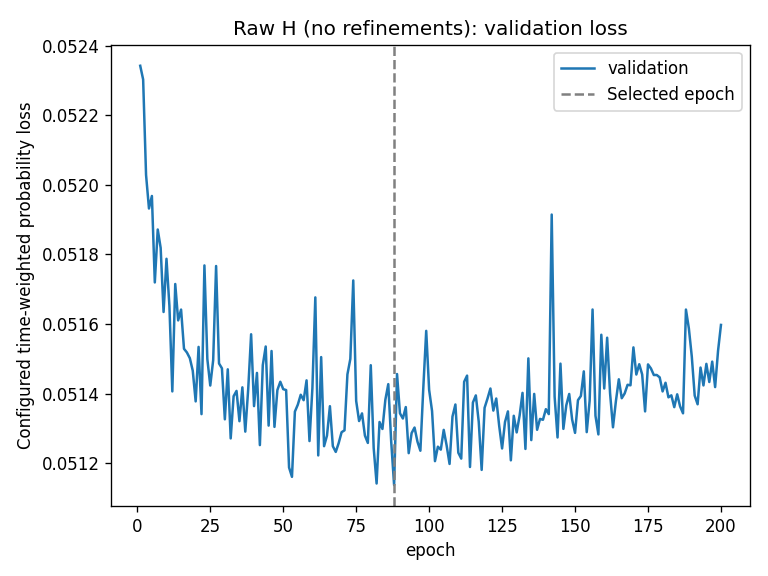

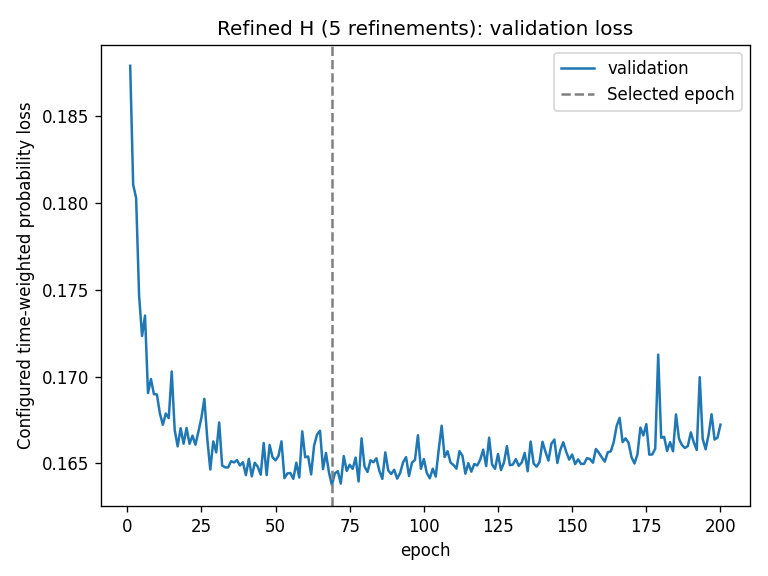

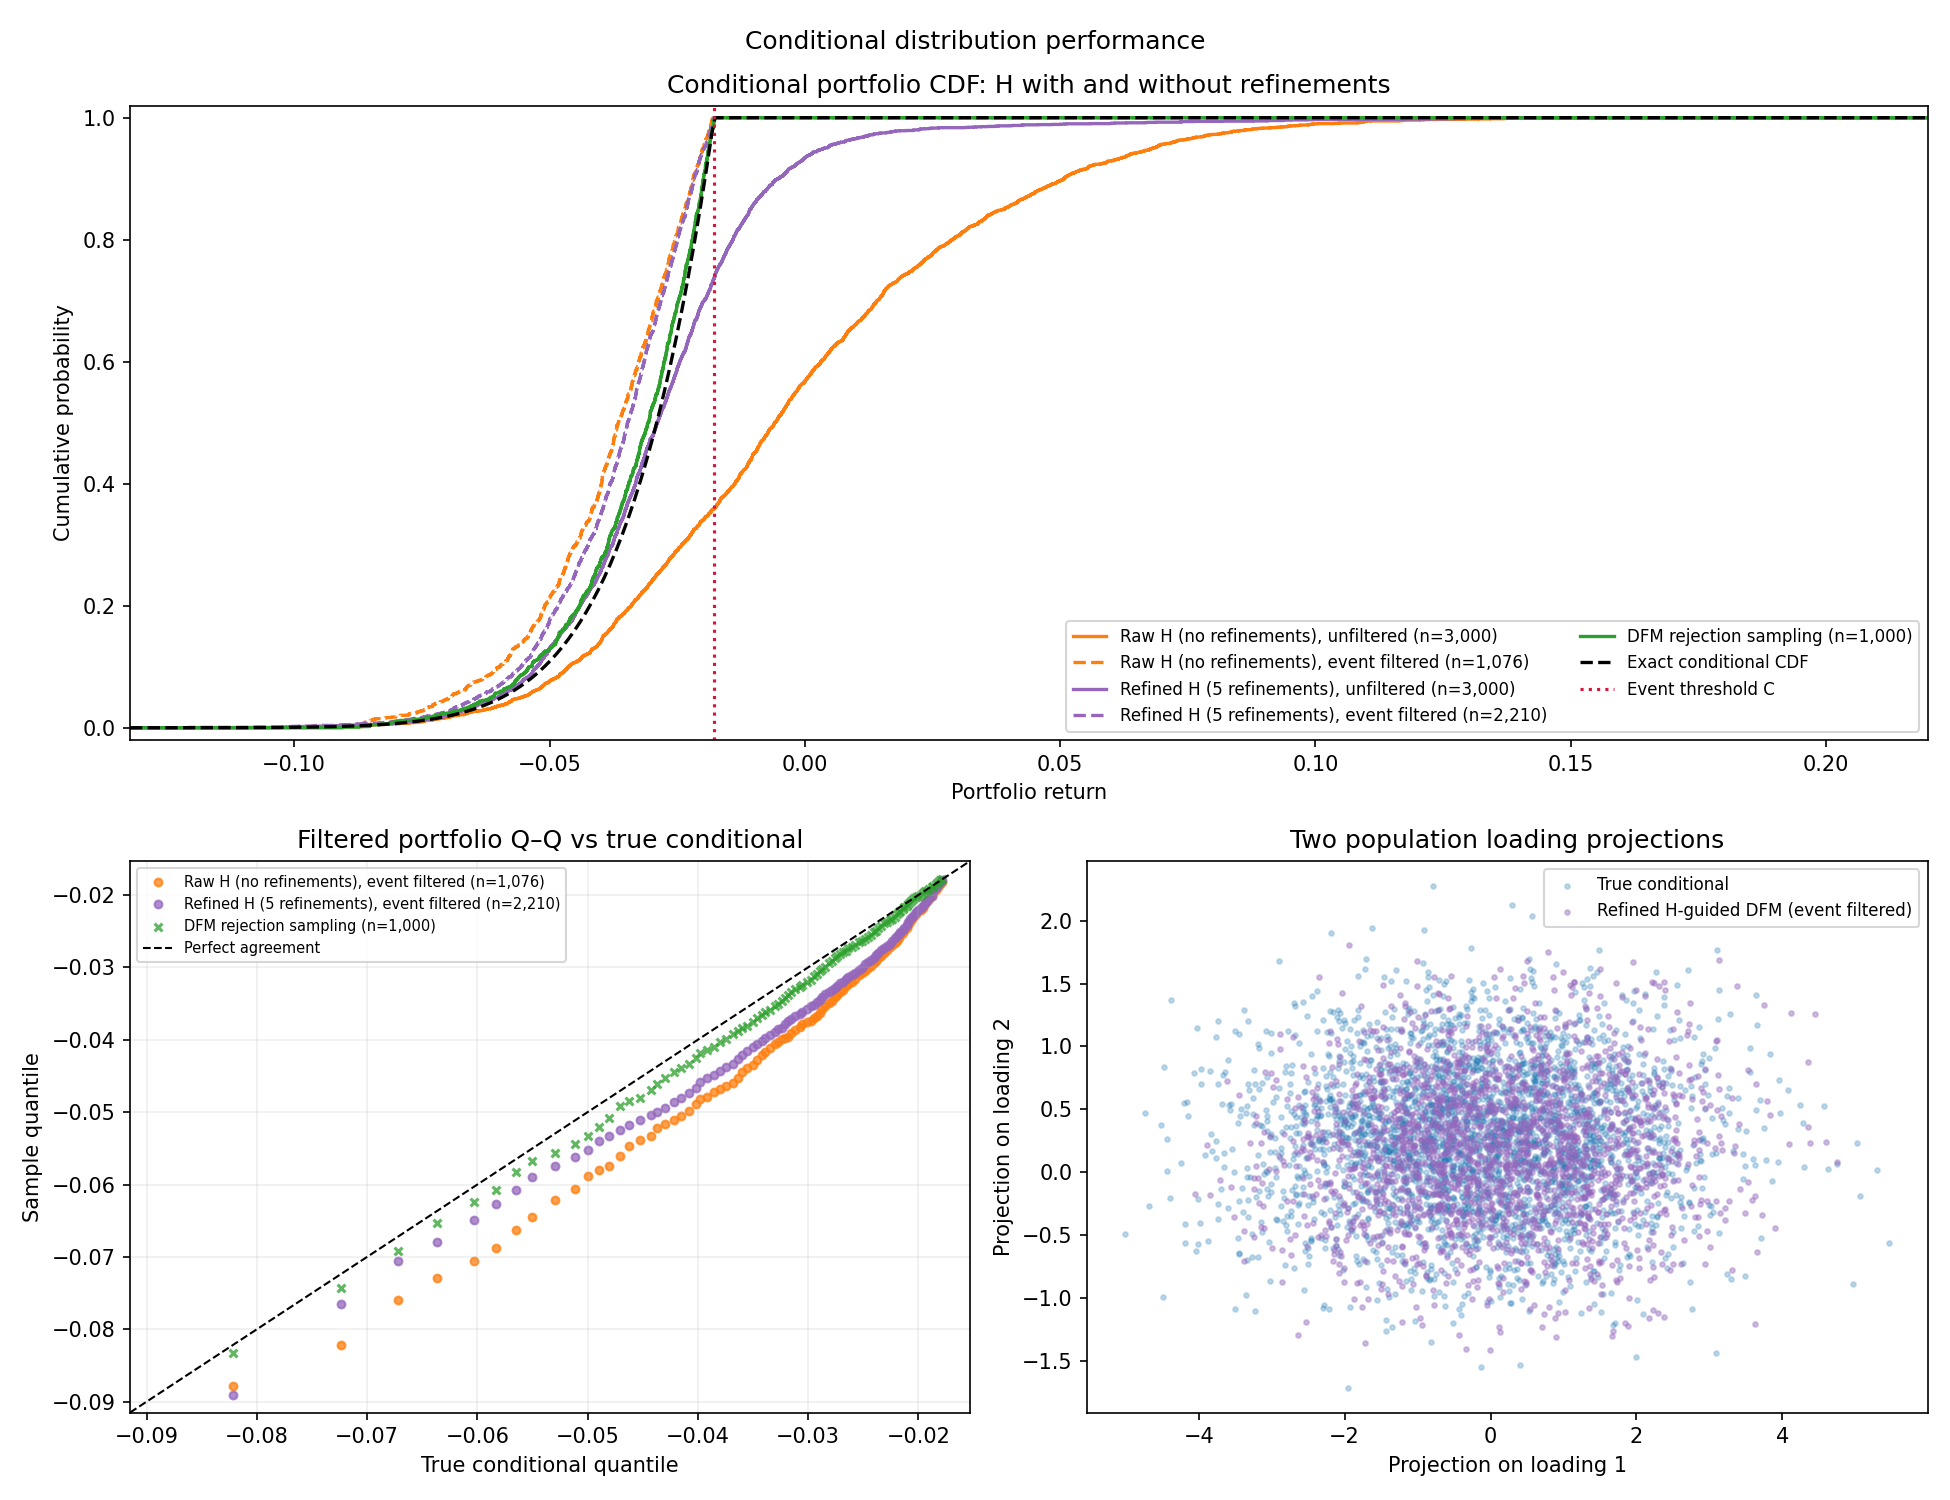

Raw versus refined H comparison saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z/h_comparison.png


In [26]:

gaussian_results = run_gaussian_conditional_simulation(
    CONFIG, OUTPUT,
    epochs=10 if CONFIG.mode == "smoke" else 200,
    n_train=2_048 if CONFIG.mode == "smoke" else 10_000,
    n_validation=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_test=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_samples=CONFIG.n_eval,
    tail=0.05,
    widths=(64, 64),
    log_remaining_time=True,
    compare_raw_h=True,  # Also train Raw H without any of the five refinements.
    h_training_options=dict(
        normalize_inputs=True, loss="bce", late_time_fraction=0.4,
        last_step_fraction=0.1, use_last_step_targets=True,
        times_per_trajectory=32,
    ),
    validation_sampling_n=128 if CONFIG.mode == "smoke" else 1_000,
    initialization_seed=2027,
    lr=1e-3,
    batch_size=64,
    path_batch_size=256,
    train_seeds={"train": 32001, "validation": 32002, "test": 32003, "shuffle": 32004},
    sample_batch_size=256,
    initialization_max_proposals=None,  # Global cap: max(100 * n_samples, sample_batch_size).
    guided_seed=42001,
    truth_seed=42002,
    assessment_settings=ConditionalAssessmentConfig(
        rejection_n=128 if CONFIG.mode == "smoke" else 1_000,
        rejection_batch_size=256,
        rejection_max_proposals=10_000 if CONFIG.mode == "smoke" else 50_000,
        rejection_reference_max_proposals=10_000 if CONFIG.mode == "smoke" else 50_000,
        rejection_seed=42003, rejection_reference_seed=42004,
        truth_reference_seed=42005, projection_seed=42006, matching_seed=42007,
        projections=64,
    ),
)
gaussian_raw_h_results = gaussian_results["raw_h_results"]
gaussian_guided_samples = gaussian_results["guided_samples"]
gaussian_true_conditional_samples = gaussian_results["true_conditional_samples"]
gaussian_filtered_guided_samples = gaussian_results["filtered_guided_samples"]
gaussian_rejection_samples = gaussian_results["rejection_samples"]
gaussian_independent_rejection_samples = gaussian_results["independent_rejection_samples"]
gaussian_independent_true_conditional_samples = gaussian_results["independent_true_conditional_samples"]
gaussian_conditional_metrics = gaussian_results["comparison_metrics"]


In [27]:
if "raw_h_results" not in gaussian_results:
    raise RuntimeError(
        "Both H variants are required. Reopen this notebook from disk and rerun the H cells."
    )
print("Validation curves and conditional performance figure saved under:", OUTPUT)


Validation curves and conditional performance figure saved under: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z


### Exact conditional moments

For Gaussian truth let $z=(C-a)/\sqrt v$ and $\lambda=\phi(z)/\Phi(z)$. Then

$$
\mathbb E[R\mid w^\top R\le C]=\mu-\frac{\Sigma w}{\sqrt v}\lambda,
$$

$$
\operatorname{Cov}(R\mid w^\top R\le C)
=\Sigma-\frac{(\Sigma w)(\Sigma w)^\top}{v}\lambda(\lambda+z).
$$

`population.moments(c=C)` returns these exact moments. The conditional law is a
truncated multivariate Gaussian, not an ordinary Gaussian with these moments.
`population.sample(N, rng, c=C)` draws it by replacing an unconditional Gaussian
draw's portfolio coordinate with an independent truncated-normal draw, while
preserving the independent Gaussian regression residual. `population.cdf(p,c=C)`
is the exact conditional portfolio CDF.


In [28]:
conditional_population = gaussian_results["population"]
conditional_threshold = gaussian_results["threshold"]
conditional_mean, conditional_covariance = conditional_population.moments(c=conditional_threshold)
mean_scale = np.sqrt(np.trace(conditional_population.moments()[1]))
conditional_groups = {
    "guided": gaussian_guided_samples,
    "filtered": gaussian_filtered_guided_samples,
    "raw_h_guided": gaussian_raw_h_results["guided_samples"],
    "raw_h_filtered": gaussian_raw_h_results["filtered_guided_samples"],
    "truth": gaussian_true_conditional_samples,
    "truth_reference": gaussian_independent_true_conditional_samples,
    "rejection": gaussian_rejection_samples,
    "rejection_reference": gaussian_independent_rejection_samples,
}
conditional_moment_rows = []
for source, samples in conditional_groups.items():
    rejection_status = gaussian_results["rejection_diagnostics"].get(source, {}).get("status", "")
    row = {"source": source, "n": len(samples), "status": "ok",
           "mean_error": None, "covariance_error": None,
           "diversity_trace_ratio": None, "portfolio_population_ks": None}
    if rejection_status.startswith("nonfinite"):
        row["status"] = rejection_status
    elif len(samples) < 2:
        row["status"] = "insufficient_samples"
    else:
        samples = np.asarray(samples, dtype=np.float64)
        sample_covariance = np.cov(samples, rowvar=False)
        row.update(
            mean_error=float(np.linalg.norm(samples.mean(0) - conditional_mean) / mean_scale),
            covariance_error=float(
                np.linalg.norm(sample_covariance - conditional_covariance)
                / np.linalg.norm(conditional_covariance)
            ),
            diversity_trace_ratio=float(np.trace(sample_covariance) / np.trace(conditional_covariance)),
            portfolio_population_ks=float(kstest(
                samples @ conditional_population.w, conditional_population.cdf,
                args=(conditional_threshold,),
            ).statistic),
        )
    conditional_moment_rows.append(row)
conditional_moment_metrics = pd.DataFrame(conditional_moment_rows)
display(conditional_moment_metrics.round(4))
conditional_moment_metrics.to_csv(gaussian_results["sample_output"] / "conditional_moments.csv", index=False)
write_json(gaussian_results["sample_output"] / "conditional_moments.json", conditional_moment_rows)

,source,n,status,mean_error,covariance_error,diversity_trace_ratio,portfolio_population_ks
0,guided,3000,ok,0.1358,0.2006,1.1383,0.2633
1,filtered,2210,ok,0.0969,0.1977,1.1028,0.1825
2,raw_h_guided,3000,ok,0.2227,0.3464,1.2237,0.6413
3,raw_h_filtered,1076,ok,0.0890,0.2493,1.0606,0.2066
4,truth,3000,ok,0.0204,0.0650,0.9999,0.0125
5,truth_reference,3000,ok,0.0135,0.0754,0.9873,0.0094
6,rejection,1000,ok,0.1207,0.1700,1.1019,0.0593
7,rejection_reference,1000,ok,0.1509,0.1790,1.1023,0.0476


## Recorded results: Raw H versus Refined H at $d=128,k=8$

These values come from the [saved standard run](artifacts/synthetic_unconditional_benchmark/standard_20261106T130902827540Z)
whose outputs are stored in this notebook (seed 42, $d=128,k=8$, 5% equal-weight
portfolio tail, $C=-0.017746$). Rerunning the notebook writes a new folder and
changes these numbers.

Raw H and Refined H were trained against the same frozen `pca_balanced` DFM
(selected epoch 912) on the same training, validation, and test trajectories.
Their guided samples are compared with the same truth and DFM rejection draws.

| Metric | Raw H | Refined H | DFM rejection |
| --- | ---: | ---: | ---: |
| Output rows before additional event filtering | 3,000 | 3,000 | 1,000 |
| Output event rate | 35.87% | 73.67% | 100% |
| Filtered rows used for analytic KS | 1,076 | 2,210 | 1,000 |
| Raw portfolio KS vs analytic conditional truth | 0.6413 | 0.2633 | 0.0593 |
| Filtered portfolio KS vs analytic conditional truth | 0.2066 | 0.1825 | 0.0593 |
| Raw KS vs DFM rejection, matched n=1,000 | 0.627 | 0.265 | 0.037* |
| Filtered KS vs DFM rejection, matched n=1,000 | 0.154 | 0.130 | 0.037* |
| Raw portfolio W1 vs DFM rejection, matched n=1,000 | 0.03193 | 0.00687 | 0.00086* |
| Filtered portfolio W1 vs DFM rejection, matched n=1,000 | 0.00490 | 0.00303 | 0.00086* |
| Raw sliced W1 vs DFM rejection, matched n=1,000 | 0.04186 | 0.03242 | 0.02154* |
| Filtered sliced W1 vs DFM rejection, matched n=1,000 | 0.05599 | 0.02737 | 0.02154* |

\* The DFM rejection distance baseline compares two independent rejection draws.
It describes finite-sample variation within the same numerical conditional law.
Rejection outputs already satisfy the event because violating proposals are
discarded, so their raw and filtered entries coincide.

Analytic KS uses all available rows, with counts shown above; its columns have
different sample sizes. For reference, two independent true conditional draws of
1,000 rows give KS 0.038. The comparisons against DFM rejection use equal sample
sizes.

Both H models were also evaluated on identical held-out unguided test states.
The gradient metrics use states whose exact last-step probability lies in
$(0.01,0.99)$.

| Diagnostic | Raw H | Refined H |
| --- | ---: | ---: |
| Held-out Brier loss (constant baseline 0.04660) | 0.04556 | 0.04533 |
| First-layer Tanh saturation | 76.23% | 15.72% |
| Last-step probability RMSE | 0.13213 | 0.01974 |
| Ambient log-probability gradient relative RMSE, n=381 | 0.9977 | 0.2799 |
| Mean gradient cosine similarity, n=381 | 0.2739 | 0.9954 |

Both models reach almost the same held-out Brier loss, which is only slightly
below the constant baseline. Their late-time probabilities and gradients differ
sharply, however. Raw H's guidance gradient is close to uninformative (cosine 0.27,
relative RMSE near 1), and its guided output satisfies the event only 36% of the
time. Refined H recovers the last-step gradient direction (cosine 0.995) and
roughly doubles the event rate. Its distances are lower than Raw H's on every
row of the first table.

Event violations and conditional distribution error remain. Refined H's filtered
KS (0.130) and W1 against DFM rejection are still several times the
rejection-vs-rejection discrepancy. DFM rejection itself departs from the
analytic conditional law (KS 0.0593 versus the truth-vs-truth level 0.038),
which reflects error in the learned DFM rather than in conditioning.
This comparison applies all five refinements together; it does not isolate their
individual effects.
